# Tâche A4 — 1.3 Corrélations et première comparaison (rénovés / non rénovés)

**Projet d'économétrie appliquée** · Consommation d'énergie et rénovation thermique

**Entrée** : `data/processed/logements_propres.csv` (1 998 logements).

**Contenu (énoncé §1.3)**
1. Matrice de corrélation des variables continues et heatmap.
2. Comparaison de la consommation moyenne des logements rénovés et non rénovés, avec test de significativité de la différence.
3. Discussion : les rénovés consomment-ils moins ? La rénovation est-elle inefficace ? Au moins deux explications (retour en partie 6).

**Rappel des tests utilisés** (cours « Tests ») : pour deux groupes de tailles $n_1, n_0$, la statistique de Welch est
$$t=\frac{\bar X_1-\bar X_0}{\sqrt{s_1^2/n_1+s_0^2/n_0}}$$
qui ne suppose pas l'égalité des variances (prudent ici : les variances des deux groupes diffèrent).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
PROC, FIG, TAB = ROOT / "data" / "processed", ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
df = pd.read_csv(PROC / "logements_propres.csv")
print("Observations :", len(df))

Observations : 1998


## 1. Matrice de corrélation des variables continues

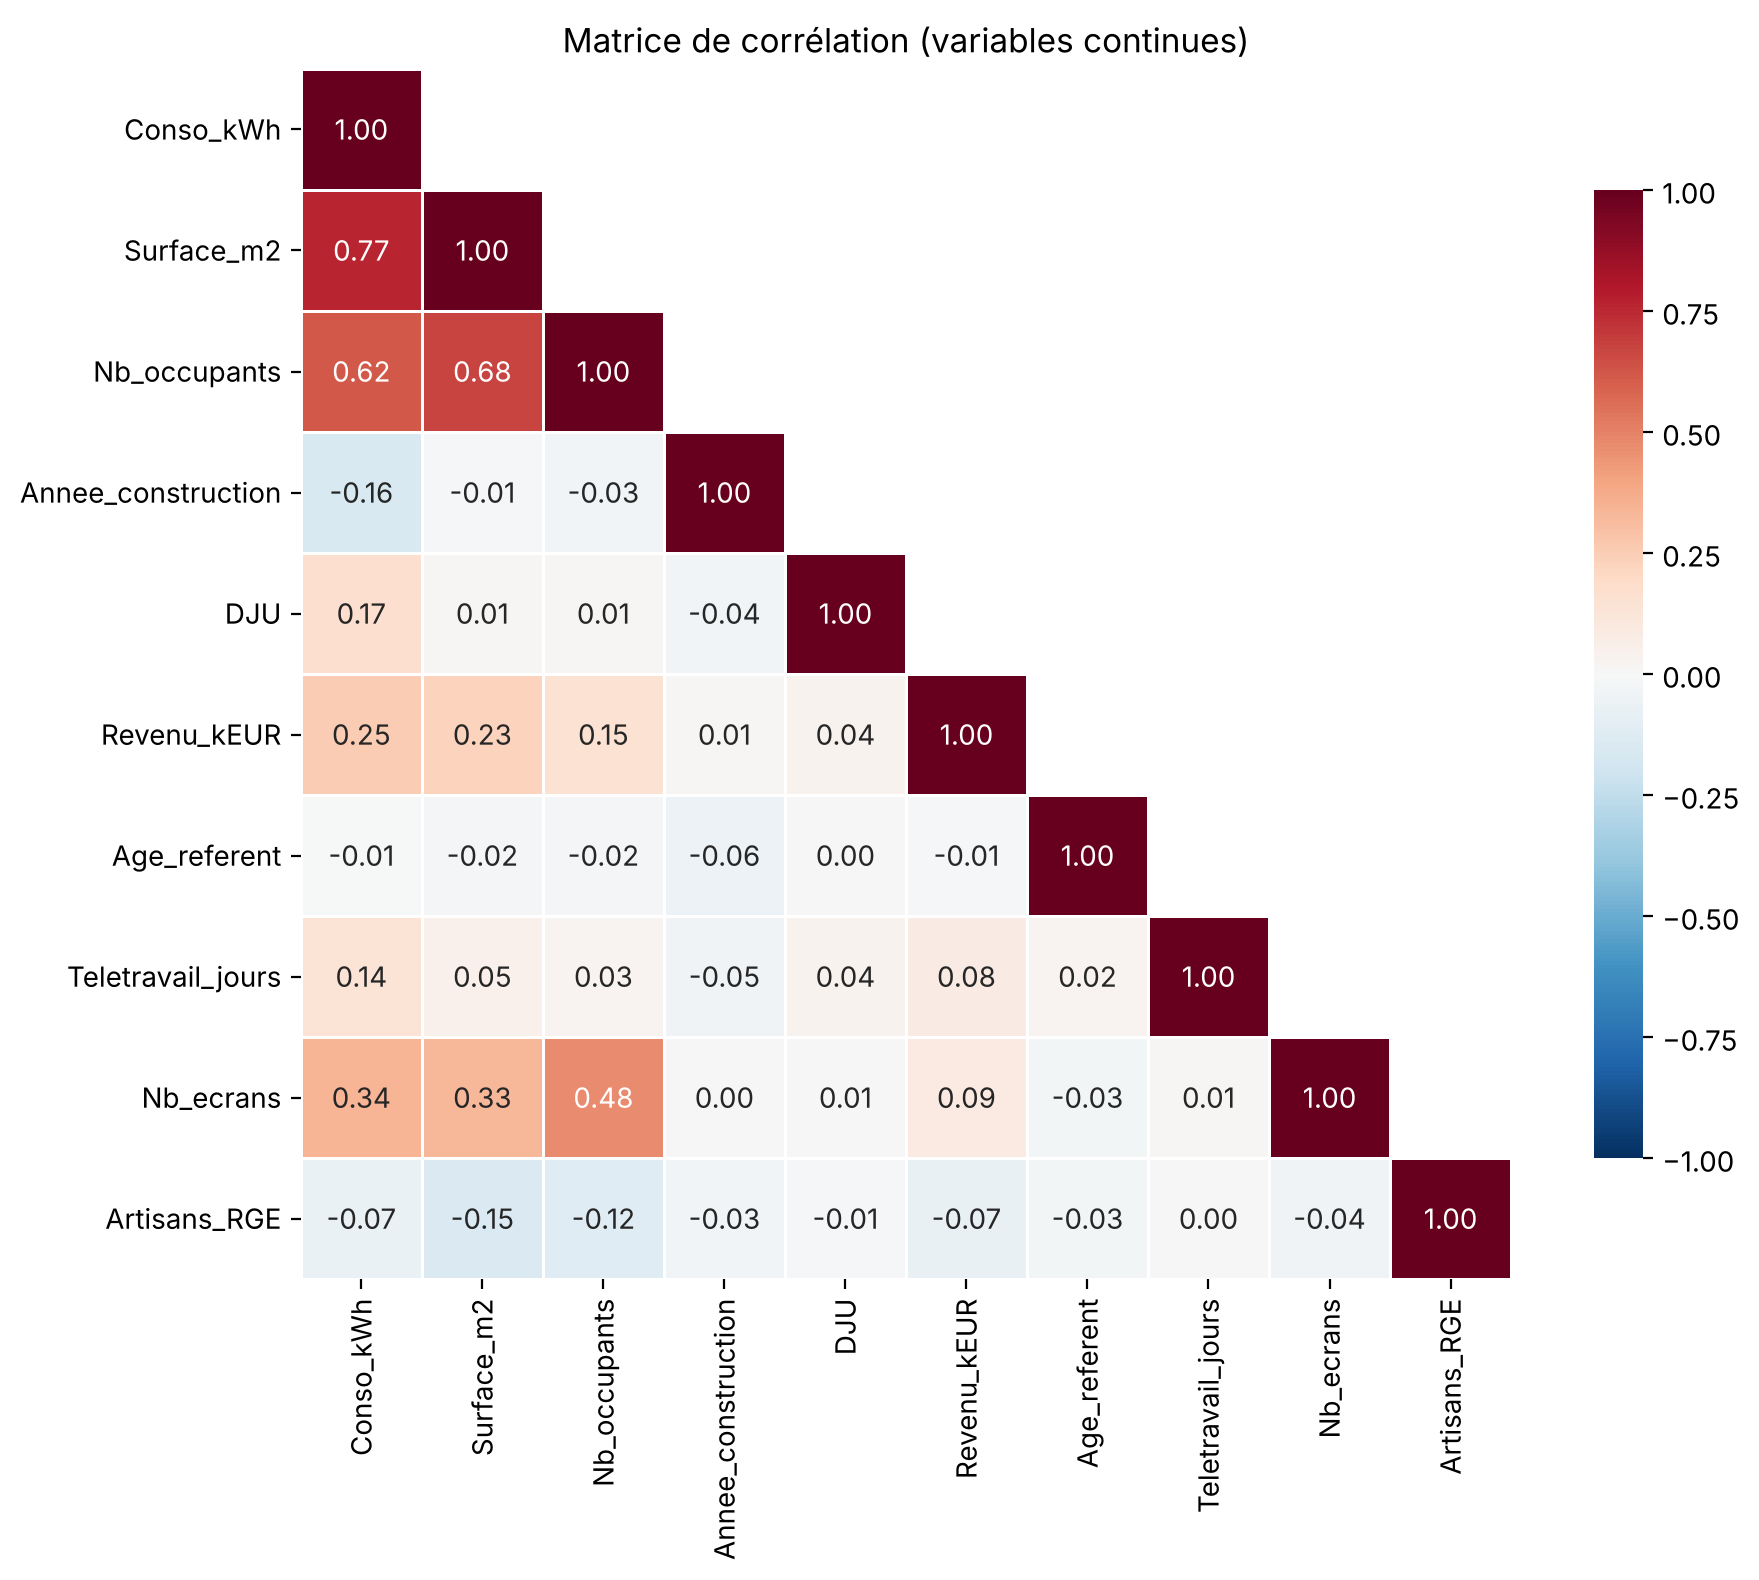

,Surface_m2,Nb_occupants,Nb_ecrans,Revenu_kEUR,DJU,Teletravail_jours,Age_referent,Artisans_RGE,Annee_construction
corr. avec Conso_kWh,0.77,0.62,0.34,0.25,0.17,0.14,-0.01,-0.07,-0.16


In [2]:
continues = ["Conso_kWh", "Surface_m2", "Nb_occupants", "Annee_construction", "DJU", "Revenu_kEUR",
             "Age_referent", "Teletravail_jours", "Nb_ecrans", "Artisans_RGE"]
corr = df[continues].corr()
corr.round(3).to_csv(TAB / "a4_matrice_correlation.csv")

fig, ax = plt.subplots(figsize=(10, 8))
masque = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=masque, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            linewidths=.5, cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Matrice de corrélation (variables continues)")
plt.tight_layout(); plt.savefig(FIG / "a4_heatmap_correlation.png", dpi=150); plt.show()
corr["Conso_kWh"].drop("Conso_kWh").sort_values(ascending=False).round(2).to_frame("corr. avec Conso_kWh").T

**Lecture.**

- `Conso_kWh` est corrélée surtout à la **surface** (0,77) et au **nombre d'occupants** (0,62), puis aux écrans (0,34), au revenu (0,25), aux DJU (0,17) et à l'année de construction (−0,16 : les logements récents consomment moins).
- Les variables explicatives sont elles-mêmes liées : **surface et occupants (0,68)**, occupants et écrans (0,48). C'est un signal de multicolinéarité modérée à surveiller en 3.1 (VIF), non un problème en soi.
- L'âge du référent et les artisans RGE sont quasiment non corrélés à la consommation (|r| ≤ 0,07).
- Une corrélation mesure une liaison linéaire **brute** : elle ne tient pas compte des autres variables (par exemple la corrélation des DJU avec la consommation est faible car les DJU sont indépendants de la surface, mais l'effet *toutes choses égales par ailleurs* est bien plus net, voir §2).

## 2. Consommation moyenne : rénovés contre non rénovés

In [3]:
a = df.loc[df["Renovation"] == 1, "Conso_kWh"]
b = df.loc[df["Renovation"] == 0, "Conso_kWh"]
resume = pd.DataFrame({"effectif": [len(b), len(a)], "moyenne": [b.mean(), a.mean()],
                       "médiane": [b.median(), a.median()], "écart-type": [b.std(), a.std()]},
                      index=["Non rénovés (0)", "Rénovés (1)"]).round(0)
display(resume)

welch = stats.ttest_ind(a, b, equal_var=False)
diff = a.mean() - b.mean()
se = np.sqrt(a.var() / len(a) + b.var() / len(b))
mw = stats.mannwhitneyu(a, b)
tests = pd.Series({"Écart de moyennes (rénovés − non rénovés), kWh": diff,
                   "IC 95 % borne basse": diff - 1.96 * se, "IC 95 % borne haute": diff + 1.96 * se,
                   "t de Welch": welch.statistic, "p-valeur (Welch)": welch.pvalue,
                   "p-valeur Mann-Whitney": mw.pvalue}).round(4)
tests.to_csv(TAB / "a4_test_renovation.csv")
tests

,effectif,moyenne,médiane,écart-type
Non rénovés (0),1274,14478.0,12466.0,8259.0
Rénovés (1),724,17216.0,15172.0,9267.0


Écart de moyennes (rénovés − non rénovés), kWh    2737.8536
IC 95 % borne basse                               1924.6131
IC 95 % borne haute                               3551.0941
t de Welch                                           6.5985
p-valeur (Welch)                                     0.0000
p-valeur Mann-Whitney                                0.0000
dtype: float64

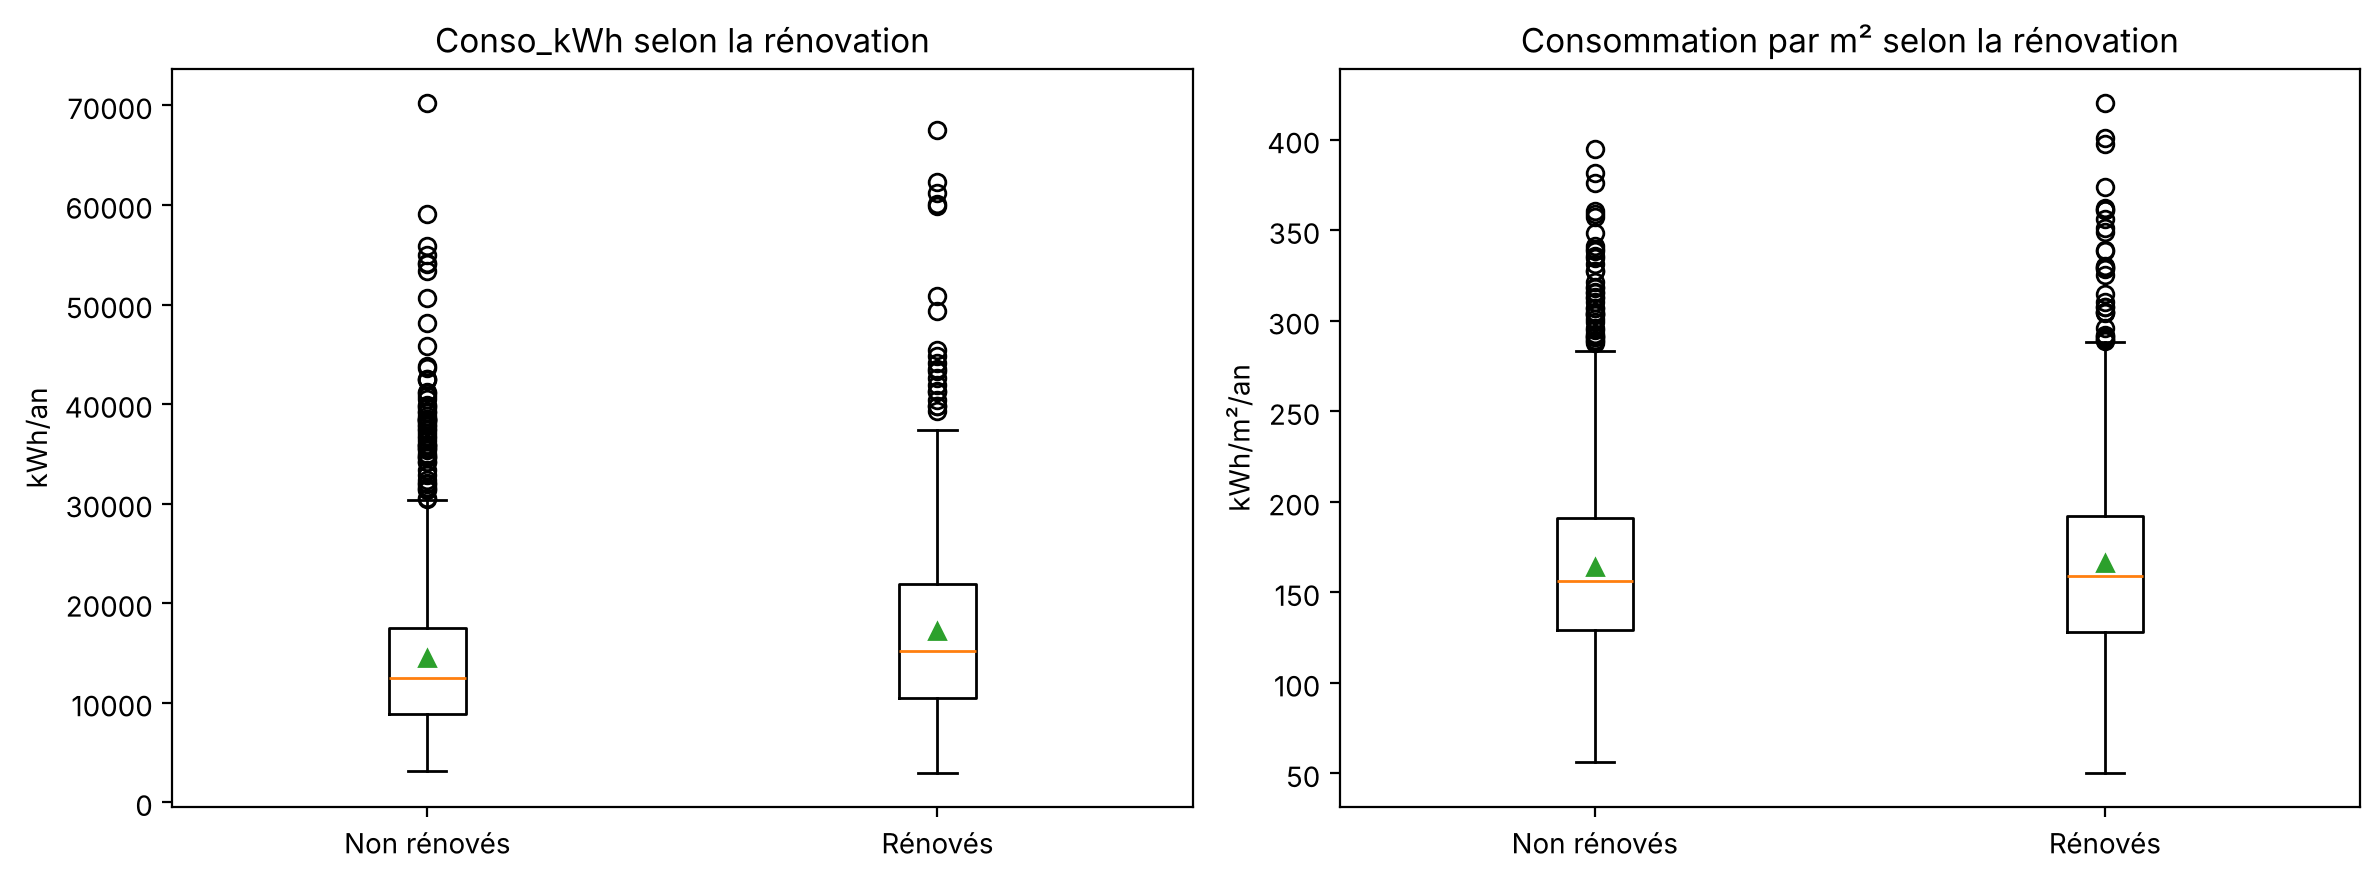

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].boxplot([b, a], tick_labels=["Non rénovés", "Rénovés"], showmeans=True)
ax[0].set_title("Conso_kWh selon la rénovation"); ax[0].set_ylabel("kWh/an")
df["Conso_par_m2"] = df["Conso_kWh"] / df["Surface_m2"]
ax[1].boxplot([df.loc[df["Renovation"] == 0, "Conso_par_m2"], df.loc[df["Renovation"] == 1, "Conso_par_m2"]],
              tick_labels=["Non rénovés", "Rénovés"], showmeans=True)
ax[1].set_title("Consommation par m² selon la rénovation"); ax[1].set_ylabel("kWh/m²/an")
plt.tight_layout(); plt.savefig(FIG / "a4_conso_renovation.png", dpi=150); plt.show()

**Résultat.** Les logements rénovés consomment **plus**, pas moins : 17 216 kWh/an en moyenne contre 14 478 pour les non rénovés, soit **+2 738 kWh** (IC à 95 % : [1 925 ; 3 551]). La différence est hautement significative (Welch $t$ = 6,60 ; p ≈ 6·10⁻¹¹ ; Mann-Whitney p ≈ 1·10⁻¹³).

## 3. Pourquoi ? Composition des deux groupes

In [5]:
vars_comp = ["Surface_m2", "Maison", "Proprietaire", "Revenu_kEUR", "Annee_construction", "Nb_occupants", "DJU", "Age_referent"]
rows = []
for c in vars_comp:
    x, y = df.loc[df["Renovation"] == 1, c], df.loc[df["Renovation"] == 0, c]
    rows.append({"variable": c, "moy. non rénovés": y.mean(), "moy. rénovés": x.mean(),
                 "écart standardisé": (x.mean() - y.mean()) / np.sqrt((x.var() + y.var()) / 2),
                 "p-valeur (Welch)": stats.ttest_ind(x, y, equal_var=False).pvalue})
comp = pd.DataFrame(rows).set_index("variable").round(3)
comp.to_csv(TAB / "a4_composition_renovation.csv")
display(comp)

pm2 = df.groupby("Renovation")["Conso_par_m2"].agg(["mean", "median"]).round(1)
t_m2 = stats.ttest_ind(df.loc[df["Renovation"] == 1, "Conso_par_m2"], df.loc[df["Renovation"] == 0, "Conso_par_m2"], equal_var=False)
print("Consommation par m² :"); display(pm2)
print(f"Test de Welch sur la conso par m² : t = {t_m2.statistic:.2f}, p = {t_m2.pvalue:.3f}")
print("\nPart de ménages rénovés selon le tirage au sort du chèque :")
display(df.groupby("Cheque_renovation")["Renovation"].mean().round(3).rename("part rénovés"))

,moy. non rénovés,moy. rénovés,écart standardisé,p-valeur (Welch)
variable,,,,
Surface_m2,88.600,103.913,0.384,0.000
Maison,0.476,0.714,0.500,0.000
Proprietaire,0.421,0.778,0.782,0.000
Revenu_kEUR,39.622,47.337,0.357,0.000
Annee_construction,1970.558,1966.007,-0.126,0.007
Nb_occupants,2.998,3.280,0.212,0.000
DJU,2403.145,2404.954,0.005,0.911
Age_referent,51.987,51.785,-0.014,0.768


Consommation par m² :


,mean,median
Renovation,,
0,164.1,156.1
1,166.1,158.9


Test de Welch sur la conso par m² : t = 0.79, p = 0.427

Part de ménages rénovés selon le tirage au sort du chèque :


Cheque_renovation
0    0.289
1    0.589
Name: part rénovés, dtype: float64

**Lecture.**

- Les rénovés sont **très différents** des non rénovés : logements plus grands (104 m² contre 89), plus souvent des maisons (71 % contre 48 %), propriétaires (78 % contre 42 %), revenus plus élevés (47,3 k€ contre 39,6 k€), un peu plus anciens et plus peuplés. En revanche, les DJU (climat) et l'âge du référent sont identiques.
- **Rapportée à la surface**, la consommation est quasiment la même : 166 kWh/m² pour les rénovés contre 164 pour les non rénovés (p = 0,43). L'écart brut de 2 738 kWh reflète donc surtout la taille des logements.
- Le chèque tiré au sort double presque la probabilité de rénover (59 % contre 29 %) : il constitue une variation de la rénovation indépendante des autres caractéristiques (partie 6).

## 4. Réponse à la question de l'énoncé

> *Les logements rénovés consomment-ils moins ? Peut-on en conclure que la rénovation est inefficace ?*

**Non et non.** Les rénovés consomment plus en moyenne, mais on ne peut pas en conclure que la rénovation est inefficace : la comparaison brute confond l'effet de la rénovation avec celui des caractéristiques des ménages qui rénovent.

**Explication 1 — Effet de composition (variables omises).** Les ménages qui rénovent possèdent des logements plus grands (maisons, propriétaires, plus aisés). La surface est le premier déterminant de la consommation (corrélation 0,77) : à surface égale, l'écart disparaît (consommation par m² identique). Formellement, si $Renovation$ est corrélée avec des variables omises $Z$ (surface, revenu, type de logement) qui augmentent la consommation, le coefficient brut de $Renovation$ est biaisé vers le haut : $\hat\beta_{brut}=\beta+\gamma\,\mathrm{Cov}(Renovation,Z)/\mathrm{Var}(Renovation)$ (biais de variable omise, voir cours « Omitted variable bias »).

**Explication 2 — Sélection et causalité inverse.** On rénove plus souvent quand on a de gros besoins énergétiques ou une facture élevée (passoire thermique, grande maison) : la forte consommation *cause* la rénovation, pas l'inverse. La rénovation est donc endogène. Une consommation observée *après* travaux peut rester élevée parce qu'elle était très élevée *avant*.

**Explication 3 — Effet rebond.** Après des travaux, la facture baisse et les ménages peuvent se chauffer davantage ou à plus haute température : une partie de l'économie théorique est consommée en confort supplémentaire.

**Suite.** La partie 2 contrôle les caractéristiques observables par régression multiple. La partie 6 traite l'endogénéité avec le chèque tiré au sort comme variable instrumentale ($Cheque\_renovation$), qui est exogène par construction.

## 5. Synthèse pour le rapport (partie 1.3)

- Corrélations de `Conso_kWh` : surface 0,77 ; occupants 0,62 ; écrans 0,34 ; revenu 0,25 ; DJU 0,17 ; année de construction −0,16. Corrélation surface–occupants : 0,68.
- Rénovés : 17 216 kWh/an (n = 724) ; non rénovés : 14 478 (n = 1 274) ; écart +2 738 kWh, significatif (Welch p ≈ 6·10⁻¹¹).
- Par m², aucune différence (166 contre 164 kWh/m², p = 0,43) : l'écart brut vient de la composition (maisons, propriétaires, grandes surfaces).
- La comparaison brute ne permet aucune conclusion causale (variables omises, causalité inverse, effet rebond). Le chèque (59 % contre 29 % de rénovés) servira d'instrument en partie 6.
- Fichiers : `outputs/tables/a4_*.csv`, `outputs/figures/a4_*.png`.